# **Gold** **Price** **Prediction** **and** **Forecasting** **System** **Using** **Machine** **Learning** **and** **Python**

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

!pip install streamlit

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

In [8]:

 df = pd.read_csv("/content/gold_market_dataset.csv")
df

,Date,Open Price,High Price,Low Price,Close Price,Gold Price,Silver Price,USD to INR Rate,Inflation Rate,Crude Oil Price,...,Yearly Average Price,Moving Average,Market Trend,Day,Month,Year,Day of Week,Gold Demand,Gold Supply,Economic Condition
0,1944-09-22,2495.11,2513.29,2490.77,2505.41,2505.02,33.67,82.02,3.89,75.23,...,2438.37,2505.41,Bearish,22,9,1944,Friday,540.54,488.11,Stable
1,1944-09-23,2498.41,2510.39,2492.26,2506.50,2503.68,33.63,82.11,4.46,76.08,...,2438.37,2505.96,Bullish,23,9,1944,Saturday,627.09,546.51,Stable
2,1944-09-24,2507.28,2515.18,2500.07,2511.92,2510.21,33.51,82.04,3.71,76.09,...,2438.37,2507.94,Bullish,24,9,1944,Sunday,552.72,526.58,Stable
3,1944-09-25,2526.24,2534.04,2517.65,2519.10,2525.49,33.99,82.03,4.29,75.27,...,2438.37,2510.73,Bullish,25,9,1944,Monday,697.14,522.01,Stable
4,1944-09-26,2528.32,2531.52,2516.97,2522.27,2523.20,33.93,82.02,4.08,76.22,...,2438.37,2513.04,Bullish,26,9,1944,Tuesday,575.91,553.49,Stable
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,2026-11-06,3901.60,3916.49,3894.26,3914.22,3905.11,65.69,98.59,3.84,140.00,...,3883.01,3919.83,Bearish,6,11,2026,Friday,555.11,556.83,Stable
29996,2026-11-07,3914.11,3921.10,3908.53,3916.26,3919.61,66.05,98.56,3.53,140.00,...,3883.01,3919.30,Bearish,7,11,2026,Saturday,536.14,645.85,Stable
29997,2026-11-08,3915.35,3915.73,3908.70,3913.16,3914.64,65.90,98.57,3.33,140.00,...,3883.01,3918.83,Bearish,8,11,2026,Sunday,532.65,600.72,Stable
29998,2026-11-09,3884.86,3900.26,3879.40,3897.07,3895.77,65.61,98.52,3.46,140.00,...,3883.01,3917.65,Bearish,9,11,2026,Monday,515.65,525.96,Stable


In [9]:
df.tail(11)

,Date,Open Price,High Price,Low Price,Close Price,Gold Price,Silver Price,USD to INR Rate,Inflation Rate,Crude Oil Price,...,Yearly Average Price,Moving Average,Market Trend,Day,Month,Year,Day of Week,Gold Demand,Gold Supply,Economic Condition
29989,2026-10-31,3912.06,3916.46,3897.04,3904.98,3910.68,65.47,98.52,3.37,140.0,...,3883.01,3923.85,Bearish,31,10,2026,Saturday,572.31,510.60,Stable
29990,2026-11-01,3908.13,3919.91,3899.14,3908.94,3908.55,65.23,98.58,3.66,140.0,...,3883.01,3922.49,Bearish,1,11,2026,Sunday,568.18,568.14,Stable
29991,2026-11-02,3924.81,3938.53,3921.09,3932.45,3926.85,65.33,98.62,3.24,140.0,...,3883.01,3922.75,Bullish,2,11,2026,Monday,464.41,586.93,Stable
29992,2026-11-03,3931.59,3940.95,3923.10,3934.26,3935.67,65.50,98.62,3.56,140.0,...,3883.01,3922.37,Bullish,3,11,2026,Tuesday,555.35,545.92,Stable
29993,2026-11-04,3919.81,3930.11,3910.73,3925.02,3923.40,65.58,98.65,3.16,140.0,...,3883.01,3922.11,Bullish,4,11,2026,Wednesday,601.08,529.86,Stable
29994,2026-11-05,3913.50,3914.73,3898.18,3900.79,3910.83,65.67,98.62,3.89,140.0,...,3883.01,3920.57,Bearish,5,11,2026,Thursday,638.88,578.73,Stable
29995,2026-11-06,3901.60,3916.49,3894.26,3914.22,3905.11,65.69,98.59,3.84,140.0,...,3883.01,3919.83,Bearish,6,11,2026,Friday,555.11,556.83,Stable
29996,2026-11-07,3914.11,3921.10,3908.53,3916.26,3919.61,66.05,98.56,3.53,140.0,...,3883.01,3919.30,Bearish,7,11,2026,Saturday,536.14,645.85,Stable
29997,2026-11-08,3915.35,3915.73,3908.70,3913.16,3914.64,65.90,98.57,3.33,140.0,...,3883.01,3918.83,Bearish,8,11,2026,Sunday,532.65,600.72,Stable
29998,2026-11-09,3884.86,3900.26,3879.40,3897.07,3895.77,65.61,98.52,3.46,140.0,...,3883.01,3917.65,Bearish,9,11,2026,Monday,515.65,525.96,Stable


In [10]:
df.shape

(30000, 23)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   30000 non-null  object 
 1   Open Price             30000 non-null  float64
 2   High Price             30000 non-null  float64
 3   Low Price              30000 non-null  float64
 4   Close Price            30000 non-null  float64
 5   Gold Price             30000 non-null  float64
 6   Silver Price           30000 non-null  float64
 7   USD to INR Rate        30000 non-null  float64
 8   Inflation Rate         30000 non-null  float64
 9   Crude Oil Price        30000 non-null  float64
 10  Previous Day Price     30000 non-null  float64
 11  Daily Price Change     30000 non-null  float64
 12  Monthly Average Price  30000 non-null  float64
 13  Yearly Average Price   30000 non-null  float64
 14  Moving Average         30000 non-null  float64
 15  Ma

In [12]:
df.isnull().sum()

,0
Date,0
Open Price,0
High Price,0
Low Price,0
Close Price,0
Gold Price,0
Silver Price,0
USD to INR Rate,0
Inflation Rate,0
Crude Oil Price,0


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.mean(numeric_only=True)

,0
Open Price,3532.034295
High Price,3539.995633
Low Price,3524.107997
Close Price,3532.058398
Gold Price,3532.033126
Silver Price,39.447939
USD to INR Rate,89.652530
Inflation Rate,4.002278
Crude Oil Price,91.890719
Previous Day Price,3532.012160


In [15]:
df.describe()

,Open Price,High Price,Low Price,Close Price,Gold Price,Silver Price,USD to INR Rate,Inflation Rate,Crude Oil Price,Previous Day Price,Daily Price Change,Monthly Average Price,Yearly Average Price,Moving Average,Day,Month,Year,Gold Demand,Gold Supply
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,3532.034295,3539.995633,3524.107997,3532.058398,3532.033126,39.447939,89.652530,4.002278,91.890719,3532.012160,0.046232,3532.058434,3532.058379,3531.385933,15.729367,6.528833,1985.291767,580.203528,550.460380
std,740.601847,740.646018,740.596273,740.618140,740.594976,11.588032,5.874341,1.431683,38.689880,740.638934,12.232549,740.268146,736.506218,740.562528,8.801563,3.448908,23.712503,57.673254,33.721242
min,2220.640000,2230.710000,2208.200000,2224.190000,2225.940000,15.000000,79.990000,1.250000,40.000000,2224.190000,-53.960000,2275.010000,2384.500000,2269.190000,1.000000,1.000000,1944.000000,364.540000,400.230000
25%,2823.427500,2831.227500,2815.167500,2822.547500,2823.315000,30.410000,83.480000,2.600000,56.440000,2822.485000,-8.242500,2822.460000,2819.530000,2821.517500,8.000000,4.000000,1965.000000,540.667500,527.587500
50%,3530.755000,3538.665000,3521.850000,3530.115000,3530.350000,40.905000,90.130000,4.010000,85.790000,3530.090000,-0.020000,3532.930000,3473.160000,3530.405000,16.000000,7.000000,1985.000000,580.140000,550.320000
75%,4244.162500,4251.597500,4235.820000,4243.710000,4244.200000,47.080000,95.480000,5.410000,140.000000,4243.710000,8.440000,4244.590000,4297.620000,4244.272500,23.000000,10.000000,2006.000000,619.440000,573.412500
max,4792.090000,4800.550000,4785.200000,4796.050000,4789.450000,67.030000,99.030000,6.590000,140.000000,4796.050000,51.130000,4763.590000,4640.100000,4764.440000,31.000000,12.000000,2026.000000,789.620000,670.470000


In [16]:
df = df.ffill()

In [17]:
df.drop_duplicates(inplace=True)

print("Duplicates:", df.duplicated().sum())

Duplicates: 0


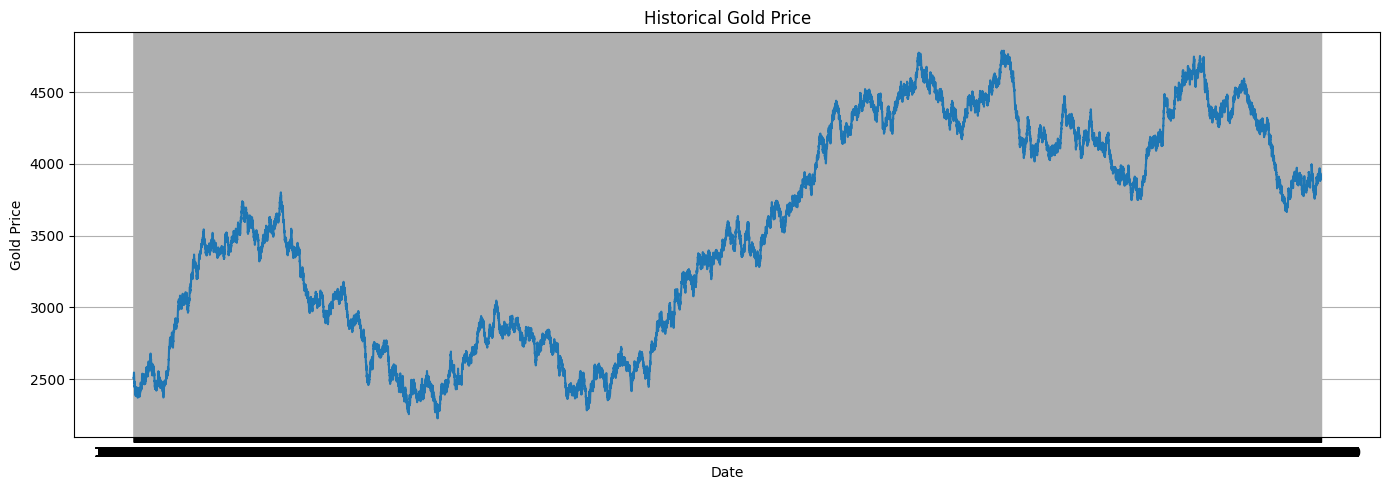

In [18]:
# 1. Historical Gold Price
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Gold Price"])
plt.title("Historical Gold Price")
plt.xlabel("Date")
plt.ylabel("Gold Price")
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
# 2. Gold vs Silver
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Gold Price"], label="Gold")
plt.plot(df["Date"], df["Silver Price"], label="Silver")
plt.title("Gold vs Silver Price")
plt.legend()
plt.grid()
plt.show()


In [ ]:
# 3. Moving Average
df["MA7"] = df["Gold Price"].shift(1).rolling(7).mean()
df["MA14"] = df["Gold Price"].shift(1).rolling(14).mean()
df["MA30"] = df["Gold Price"].shift(1).rolling(30).mean()

plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Gold Price"], label="Gold Price")
plt.plot(df["Date"], df["MA7"], label="7 Days")
plt.plot(df["Date"], df["MA14"], label="14 Days")
plt.plot(df["Date"], df["MA30"], label="30 Days")
plt.title("Gold Moving Average")
plt.legend()
plt.grid()
plt.show()


In [ ]:
import seaborn as sns

# 4. Correlation Heatmap
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(14, 9))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Gold Market Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Define Features (X) and Target (y)
# We'll use numerical columns as features to predict "Gold Price"
features = ["Open Price", "High Price", "Low Price", "Close Price", "Silver Price", "USD to INR Rate"]
X = df[features]
y = df["Gold Price"]

# 2. Split the dataset into training and testing sets
X_train, X_test, y_test, y_pred_actual = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train a Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_test)

# 4. Generate Predictions
y_pred = model.predict(X_test)

# 5. Plot Actual vs Predicted values
plt.figure(figsize=(14, 5))
plt.plot(
    y_test.values[:100],  # Plotting first 100 values for visual clarity
    label="Actual Gold Price"
)
plt.plot(
    y_pred[:100],
    label="Predicted Gold Price"
)
plt.title("Actual vs Predicted Gold Price (First 100 Test Records)")
plt.xlabel("Test Records")
plt.ylabel("Gold Price")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# 5. Gold Price Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["Gold Price"], kde=True)
plt.title("Gold Price Distribution")
plt.xlabel("Gold Price")
plt.show()

In [ ]:
import plotly.express as px

# 6. Interactive Gold Price Chart
fig = px.line(
    df,
    x="Date",
    y="Gold Price",
    title="Interactive Gold Price Analysis"
)
fig.show()

In [ ]:
# 7. Feature Relationship
fig = px.scatter(
    df,
    x="Silver Price",
    y="Gold Price",
    color="Market Trend",
    title="Gold Price vs Silver Price"
)
fig.show()

In [ ]:
#Actual vs Predicted chart
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.values,
    label="Actual Gold Price"
)

plt.plot(
    y_pred,
    label="Predicted Gold Price"
)

plt.title("Actual vs Predicted Gold Price")
plt.xlabel("Test Records")
plt.ylabel("Gold Price")
plt.legend()
plt.grid()
plt.show()


In [ ]:
from sklearn.metrics import root_mean_squared_error
#Model comparison chart

# Calculate RMSE for the Linear Regression model
lr_rmse = root_mean_squared_error(y_pred_actual, y_pred)

# Define the results dictionary containing model performance
results = {
    "model": ["Linear Regression"],
    "RMSE": [lr_rmse]
}

# Plot the comparison
plt.figure(figsize=(10, 5))

plt.bar(
    results["model"],
    results["RMSE"],
    color="skyblue",
    width=0.4
)

plt.title("Algorithm RMSE Comparison")
plt.xlabel("Algorithms")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Install required packages
!pip install -q streamlit pyngrok

import os
# Ensure the folder structure exists and save our cleaned dataframe so the dashboard can read it
os.makedirs("dataset", exist_ok=True)
df.to_csv("dataset/cleaned_gold_data.csv", index=False)

# 2. Write the Streamlit dashboard code into an external Python file 'app.py'
with open("app.py", "w") as f:
    f.write("""
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

df_dashboard = pd.read_csv("dataset/cleaned_gold_data.csv")
df_dashboard["Date"] = pd.to_datetime(df_dashboard["Date"])

st.title("Gold Price Analytics Dashboard")

# Historical chart
st.subheader("Historical Gold Price")

fig1 = px.line(
    df_dashboard,
    x="Date",
    y="Gold Price",
    title="Gold Price Trend"
)

st.plotly_chart(fig1, use_container_width=True)

# Gold and Silver
st.subheader("Gold vs Silver")

fig2 = go.Figure()

fig2.add_trace(go.Scatter(
    x=df_dashboard["Date"],
    y=df_dashboard["Gold Price"],
    name="Gold"
))

fig2.add_trace(go.Scatter(
    x=df_dashboard["Date"],
    y=df_dashboard["Silver Price"],
    name="Silver"
))

st.plotly_chart(fig2, use_container_width=True)

# Correlation
st.subheader("Market Correlation")

corr = df_dashboard.select_dtypes(
    include="number"
).corr()

fig3 = px.imshow(
    corr,
    text_auto=".2f",
    title="Correlation Heatmap"
)

st.plotly_chart(fig3, use_container_width=True)
""")

print("Successfully created 'app.py'! Run 'streamlit run app.py' with a tunnel to view it.")

In [ ]:
# Convert Date
df["Date"] = pd.to_datetime(df["Date"])


In [ ]:
# User enters year with a safe fallback to prevent ValueError on empty input
user_input = input("Enter Year (default 2023): ").strip()
year = int(user_input) if user_input.isdigit() else 2023
print(f"Selected Year: {year}")

In [ ]:
# Filter selected year (fallback to 2020 if 'year' is not defined)
selected_year = year if "year" in globals() else 2020
year_data = df[df["Date"].dt.year == selected_year]

In [ ]:
# Display records
if len(year_data) > 0:
    print("Selected Year:", year)
    print("Total Records:", len(year_data))

    print(year_data)

In [ ]:
# Save selected year data if records exist
if len(year_data) > 0:
    year_data.to_csv(f"Gold_Data_{year}.csv", index=False)
    print("File Saved Successfully!")
else:
    print("No Data Available for This Year")

In [ ]:
#2: Load Dataset

df = pd.read_csv("/content/GOLD DATASET.csv")

df["Date"] = pd.to_datetime(df["Date"])


In [ ]:
#3: User Selects Year

year = int(input("Enter Year: "))

data = df[df["Date"].dt.year == year].copy()
data = data.sort_values("Date").reset_index(drop=True)

if len(data) < 10:
    raise ValueError("Not enough records for ML training")

print("Selected Year:", year)
print("Total Records:", len(data))

In [ ]:
#4: Select Features

features = [
    "Open Price",
    "High Price",
    "Low Price",
    "Silver Price",
    "USD to INR Rate",
    "Inflation Rate",
    "Crude Oil Price",
    "Previous Day Price",
    "Gold Demand",
    "Gold Supply",
    "Day",
    "Month"
]

X = data[features].fillna(0)
y = data["Gold Price"]


In [ ]:
# STEP 6: Create 4 ML Models

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}


In [ ]:
# STEP 7: Train and Evaluate
from sklearn.model_selection import train_test_split

# Split features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    mae = mean_absolute_error(y_test, prediction)
    rmse = np.sqrt(mean_squared_error(y_test, prediction))
    r2 = r2_score(y_test, prediction)

    results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

    print("\nModel:", name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

In [ ]:
# STEP 8: Compare Algorithms

result_df = pd.DataFrame(results).T

print("\nAlgorithm Comparison")
print(result_df)

# STEP 9: Best Model

best_model_name = result_df["MAE"].idxmin()

print("Best Model:", best_model_name)


Deep Learning – LSTM Algorithm

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# STEP 1: Get selected year data

gold = data[["Gold Price"]].dropna().values


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# STEP 2: Scaling
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(gold)

# STEP 3: Create sequences

sequence_length = 30

X_lstm = []
y_lstm = []

for i in range(sequence_length, len(scaled_data)):

    X_lstm.append(
        scaled_data[i-sequence_length:i]
    )

    y_lstm.append(
        scaled_data[i]
    )

X_lstm = np.array(X_lstm)
y_lstm = np.array(y_lstm)